In [3]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = PROJECT_ROOT / "data" / "processed"

train_df = pd.read_csv(DATA_DIR / "train.csv")
val_df = pd.read_csv(DATA_DIR / "val.csv")
# test.csv is NOT loaded. We open the final exam only once, at the very end.

print("Train:", train_df.shape, "| Val:", val_df.shape)

Train: (2456, 2) | Val: (492, 2)


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(lowercase = True)
X_train = vectorizer.fit_transform(train_df["sentence_clean"])
# learn words from train , then score
X_val = vectorizer.transform(val_df["sentence_clean"])
# only score, no learning

print("X_train shape:",X_train.shape)
print("Number of different words learned:",len(vectorizer.vocabulary_))

##look inside one sentence : which words got the highest scores?

i=0
print("\nSentence:", train_df["sentence_clean"][i])
row = X_train[i].toarray()[0]
words = vectorizer.get_feature_names_out()
for j in row.argsort()[::-1][:8]:
    if row[j] > 0:
        print(f"{words[j]:>15}  {row[j]:.3f}")



X_train shape: (2456, 6628)
Number of different woords learned: 6628

Sentence: According to Gran , the company has no plans to move all production to Russia , although that is where the company is growing .
           gran  0.336
       although  0.324
        growing  0.288
          plans  0.280
          where  0.261
           move  0.261
             to  0.249
        company  0.249


In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report

model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train, train_df["label"])  ##learn the points from the practice book

val_pred = model.predict(X_val)     ## answer the mock exam

print("Accuracy:",round(accuracy_score(val_df["label"],val_pred),3))
print("Macro-F1:", round(f1_score(val_df["label"], val_pred,average="macro"),3))
print()
print(classification_report(val_df["label"],val_pred,digits=3))

Accuracy: 0.827
Macro-F1: 0.734

              precision    recall  f1-score   support

    negative      0.963     0.433     0.598        60
     neutral      0.823     0.987     0.897       306
    positive      0.806     0.627     0.705       126

    accuracy                          0.827       492
   macro avg      0.864     0.682     0.734       492
weighted avg      0.836     0.827     0.812       492



In [7]:
words = vectorizer.get_feature_names_out()
for k, label in enumerate(model.classes_):
    top = model.coef_[k].argsort()[::-1][:10]  ## 10 wordswith the biggest points for this class
    print(f"{label:>8}: {[words[j] for j in top]}")

negative: ['decreased', 'down', 'fell', 'lower', 'dropped', 'declined', 'warning', 'profit', 'loss', 'than']
 neutral: ['is', 'be', 'approximately', 'not', 'will', 'stake', 'were', 'value', 'includes', 'and']
positive: ['rose', 'up', 'increase', 'increased', 'to', 'our', 'grew', 'signed', 'from', 'year']


In [8]:
##class weight == balane

model_bal = LogisticRegression(max_iter=1000, random_state=42, class_weight= "balanced")
model_bal.fit(X_train, train_df["label"])
val_pred_bal = model_bal.predict(X_val)

print("Accuracy:", round(accuracy_score(val_df["label"],val_pred_bal),3))
print("Macro-F1:", round(f1_score(val_df["label"],val_pred_bal,average="macro"),3))
print()
print(classification_report(val_df["label"], val_pred_bal, digits=3))

Accuracy: 0.835
Macro-F1: 0.783

              precision    recall  f1-score   support

    negative      0.724     0.700     0.712        60
     neutral      0.875     0.915     0.895       306
    positive      0.781     0.706     0.742       126

    accuracy                          0.835       492
   macro avg      0.793     0.774     0.783       492
weighted avg      0.832     0.835     0.833       492



In [11]:
results = []
for ngram in [(1,1),(1,2)]:
    vec = TfidfVectorizer(lowercase=True, ngram_range=ngram)
    Xtr = vec.fit_transform(train_df["sentence_clean"])
    Xva = vec.transform(val_df["sentence_clean"])
    for C in [0.1,1,10,100]:
        m= LogisticRegression(max_iter=2000, random_state=42, class_weight="balanced", C=C)
        m.fit(Xtr, train_df["label"])
        f1 = f1_score(val_df["label"], m.predict(Xva), average="macro")
        results.append({"ngram": str(ngram), "C":C, "words_learned":Xtr.shape[1],"val_macro_f1":round(f1,3)})

results_df = pd.DataFrame(results).sort_values("val_macro_f1",ascending=False)
print(results_df.to_string(index=False))

 ngram     C  words_learned  val_macro_f1
(1, 1) 100.0           6628         0.786
(1, 1)  10.0           6628         0.786
(1, 2) 100.0          33025         0.784
(1, 1)   1.0           6628         0.783
(1, 2)  10.0          33025         0.776
(1, 2)   1.0          33025         0.770
(1, 1)   0.1           6628         0.708
(1, 2)   0.1          33025         0.707


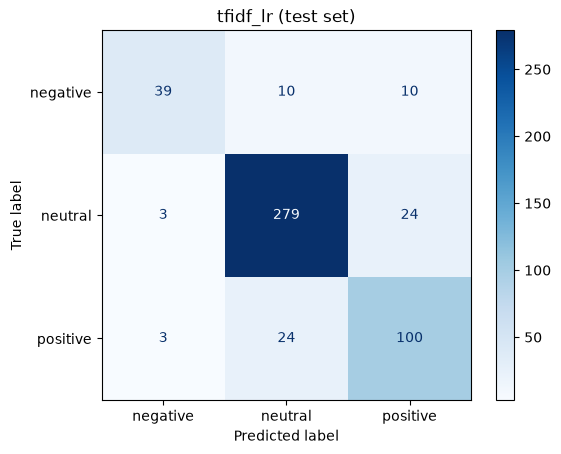

tfidf_lr on test: accuracy 0.8496 | Macro-F1 0.8059
              precision    recall  f1-score   support

    negative      0.867     0.661     0.750        59
     neutral      0.891     0.912     0.901       306
    positive      0.746     0.787     0.766       127

    accuracy                          0.850       492
   macro avg      0.835     0.787     0.806       492
weighted avg      0.851     0.850     0.848       492



In [13]:
import sys, importlib, joblib
sys.path.append(str(PROJECT_ROOT))
import src.evaluate as ev
importlib.reload(ev)

#train the final model with the frozen settings
final_vec = TfidfVectorizer(lowercase=True, ngram_range=(1,1))
X_train_final= final_vec.fit_transform(train_df["sentence_clean"])
final_model = LogisticRegression(max_iter=2000,random_state=42,class_weight="balanced",C=10)
final_model.fit(X_train_final, train_df["label"])

# save it so the app and the speed test can resue it later
MODELS_DIR = PROJECT_ROOT/ "models"
MODELS_DIR.mkdir(exist_ok=True)
joblib.dump(final_vec, MODELS_DIR / "tfidf_vectorizerjoblib")
joblib.dump(final_model, MODELS_DIR / "tfidf_lr.joblib")

##open the final exam, once
test_df =pd.read_csv(DATA_DIR /"test.csv")
test_pred = final_model.predict(final_vec.transform(test_df["sentence_clean"]))
metrics = ev.evaluate(test_df["label"], test_pred, "tfidf_lr", PROJECT_ROOT / "results")
